# 02 - Exploratory Data Analysis
Goal: understand the categorical variables, the numerical variable (price) and how price relates to time, so we can justify our modeling choices.

EDA is descriptive only: nothing is fitted here, and no statistic is used to tune a model.

In [1]:
import sys
sys.path.append('..')
import pandas as pd
from src.preprocessing import clean_data, time_split
from src.evaluation import evaluate_regression

df = clean_data(pd.read_csv('../data/us_average_prices_monthly.csv'))
train, test = time_split(df, '2024-01-01')   # older rows = train, 2024+ = test

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Column names produced by clean_data. CHECK these against df.columns and edit if they differ.
DATE, ITEM, CAT, PRICE = 'date', 'item', 'category', 'price'

missing = [c for c in (DATE, ITEM, CAT, PRICE) if c not in df.columns]
assert not missing, f"Rename the constants above to match df.columns: {list(df.columns)} (missing: {missing})"
print(df.shape, df[DATE].min().date(), "to", df[DATE].max().date())

(8869, 8) 2015-01-01 to 2026-07-01


## 1. Categorical variables
Counts of rows per category and per item.

,items,rows
category,,
Eggs,1,138
Pantry and snacks,2,208
"Meat, broad category",3,407
Drinks,4,474
Poultry,4,475
Bakery and grains,6,824
Fruit,8,859
Dairy and fats,8,906
Vegetables,9,916


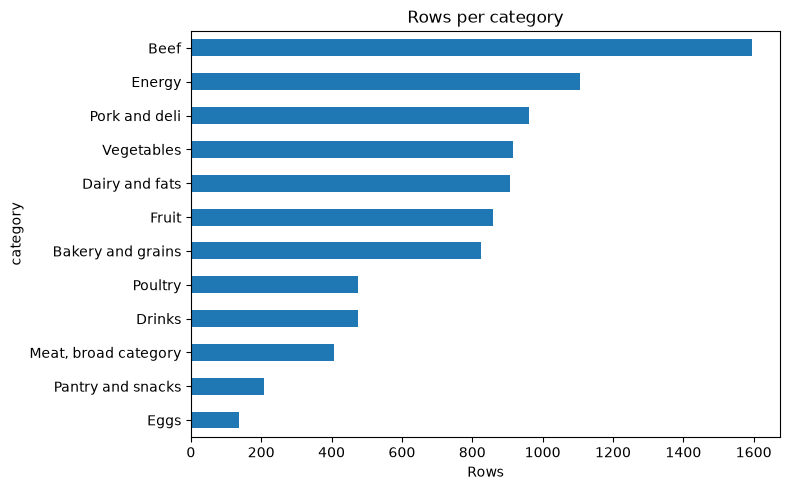

In [3]:
cat_counts = (df.groupby(CAT, observed=True)
                .agg(items=(ITEM, 'nunique'), rows=(ITEM, 'size'))
                .sort_values('rows'))
display(cat_counts)

cat_counts['rows'].plot.barh(figsize=(8, 5), title='Rows per category')
plt.xlabel('Rows'); plt.tight_layout(); plt.show()

count     74.000000
mean     119.851351
std       30.460701
min       31.000000
25%      103.000000
50%      137.000000
75%      138.000000
max      139.000000
Name: count, dtype: float64


item
Sugar, white, 33-80 oz. pkg                                           70
Steak, round, graded and ungraded, excluding USDA Prime and Choice    67
Broccoli                                                              63
Turkey, frozen, whole                                                 62
Margarine, soft, tubs                                                 58
Peppers, sweet                                                        58
Bologna, all beef or mixed                                            57
Corn, canned, any style, all sizes                                    37
Chuck roast, graded and ungraded, excluding USDA Prime and Choice     36
Pears, Anjou                                                          31
Name: count, dtype: int64

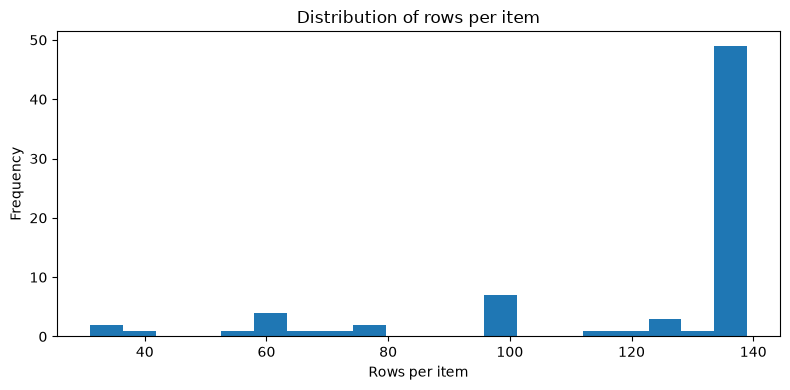

In [4]:
item_counts = df[ITEM].value_counts()
print(item_counts.describe())

# Items with the shortest history (series that stop early or start late)
display(item_counts.tail(10))

item_counts.plot.hist(bins=20, figsize=(8, 4), title='Distribution of rows per item')
plt.xlabel('Rows per item'); plt.tight_layout(); plt.show()

**What this means:** categories do not have the same number of items, and some item series are shorter than others (the report notes that 14 of 74 series stop between 2019 and 2022). Models will therefore see some items far more often than others, so we judge them on the time-based test set and not on item coverage alone. `item` is the more informative identifier (74 values vs. 12 categories), so it is our main categorical feature.

## 2. Numerical variable: price

count    8869.000000
mean        3.585699
std         2.521724
min         0.131000
25%         1.621000
50%         3.172000
75%         4.870000
max        14.727000
Name: price, dtype: float64

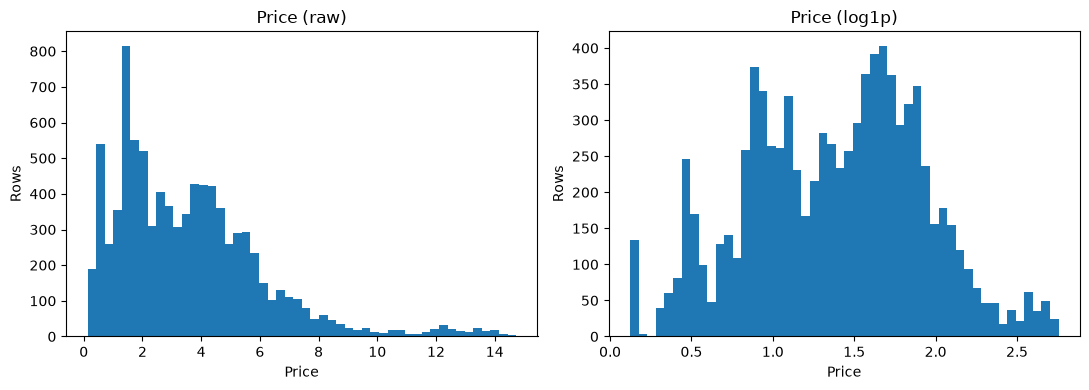

In [5]:
display(df[PRICE].describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df[PRICE], bins=50);            axes[0].set_title('Price (raw)')
axes[1].hist(np.log1p(df[PRICE]), bins=50);  axes[1].set_title('Price (log1p)')
for ax in axes: ax.set_xlabel('Price'); ax.set_ylabel('Rows')
plt.tight_layout(); plt.show()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Pantry and snacks,208.0,0.714149,0.147662,0.549,0.62200,0.6520,0.75000,1.054
Bakery and grains,824.0,1.758067,1.236417,0.356,0.78350,1.3510,2.07725,5.352
Fruit,859.0,1.926383,0.909304,0.544,1.32800,1.9780,2.48100,4.970
Vegetables,916.0,2.208809,1.466354,0.633,1.34200,1.8030,2.33225,6.971
Poultry,475.0,2.209145,0.949592,1.327,1.51150,1.7350,3.08400,4.746
Eggs,138.0,2.261688,0.982940,1.203,1.54100,1.9960,2.71425,6.227
Energy,1107.0,2.619874,1.351069,0.131,1.82600,2.7950,3.55400,5.973
Dairy and fats,906.0,3.921938,1.391851,1.043,3.16575,4.0870,4.91050,6.505
Pork and deli,960.0,4.208667,1.108942,2.516,3.56250,4.0665,4.61525,7.608


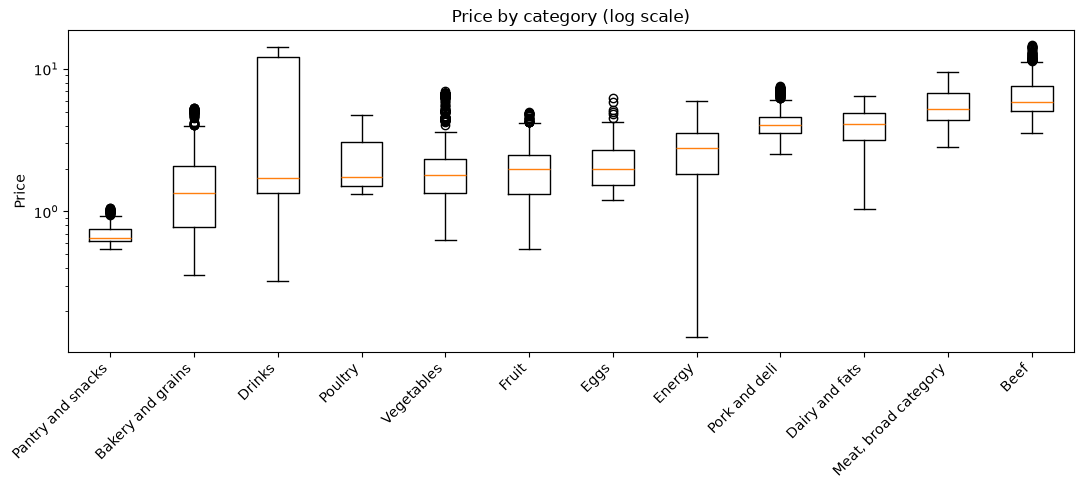

In [6]:
display(df.groupby(CAT, observed=True)[PRICE].describe().sort_values('mean'))

order = df.groupby(CAT, observed=True)[PRICE].median().sort_values().index
data = [df.loc[df[CAT] == c, PRICE] for c in order]
plt.figure(figsize=(11, 5)); plt.boxplot(data)
plt.xticks(range(1, len(order) + 1), order, rotation=45, ha='right'); plt.ylabel('Price')
plt.title('Price by category (log scale)'); plt.yscale('log'); plt.tight_layout(); plt.show()

**What this means:** prices are right-skewed and measured in very different units (per pound, per dozen, per gallon), so the range inside and across categories is wide. This is why the item identifier matters so much for prediction, and why a single overall error number (RMSE) is dominated by the most expensive items. Tree models do not need scaled inputs, but linear models do.

## 3. Relationships: time, seasonality and shocks

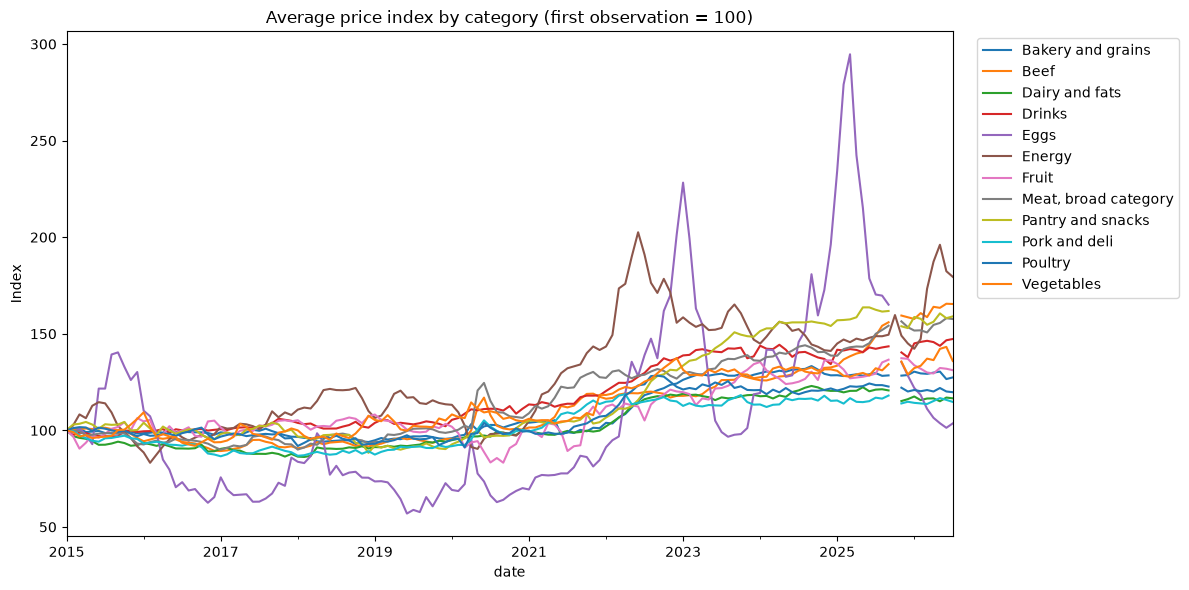

category
Energy                  79.5
Beef                    65.4
Pantry and snacks       59.0
Meat, broad category    57.6
Drinks                  47.3
Vegetables              35.9
Fruit                   31.2
Bakery and grains       27.4
Poultry                 19.8
Dairy and fats          16.6
Pork and deli           14.7
Eggs                     3.6
Name: % change, dtype: float64

In [7]:
# Index each item to 100 at its first observation so categories with different price levels are comparable
eda = df.sort_values([ITEM, DATE]).copy()
eda['price_index'] = eda[PRICE] / eda.groupby(ITEM, observed=True)[PRICE].transform('first') * 100
idx = eda.pivot_table(index=DATE, columns=CAT, values='price_index', aggfunc='mean', observed=True)

idx.plot(figsize=(12, 6), title='Average price index by category (first observation = 100)')
plt.ylabel('Index'); plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.tight_layout(); plt.show()

# Total change from first to last month, by category
display((idx.ffill().iloc[-1] - 100).sort_values(ascending=False).round(1).rename('% change'))

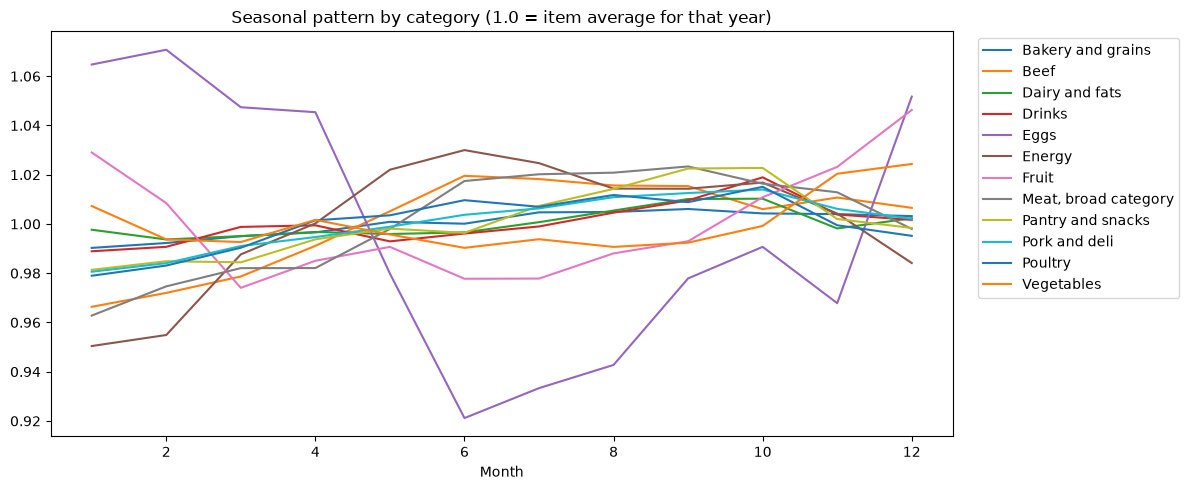

month
1     0.985
2     0.985
3     0.988
4     0.996
5     1.001
6     1.004
7     1.005
8     1.006
9     1.008
10    1.010
11    1.008
12    1.008
Name: overall seasonal ratio, dtype: float64

In [8]:
# Seasonality: price relative to the item's own average in that year (removes level and trend)
eda['year'] = eda[DATE].dt.year
eda['month'] = eda[DATE].dt.month
eda['seasonal_ratio'] = eda[PRICE] / eda.groupby([ITEM, 'year'], observed=True)[PRICE].transform('mean')

season = eda.pivot_table(index='month', columns=CAT, values='seasonal_ratio', aggfunc='mean', observed=True)
season.plot(figsize=(12, 5), title='Seasonal pattern by category (1.0 = item average for that year)')
plt.xlabel('Month'); plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.tight_layout(); plt.show()

display(eda.groupby('month')['seasonal_ratio'].mean().round(3).rename('overall seasonal ratio'))

C:\Users\Angel\AppData\Local\Temp\ipykernel_8236\1026243959.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(shocks[[DATE, ITEM, CAT, PRICE, 'pct_change']].round(2))


,date,item,category,price,pct_change
6087,2021-12-01,"Lettuce, romaine",Vegetables,3.27,61.11
7975,2016-11-01,"Strawberries, dry pint",Fruit,3.16,42.82
8080,2025-12-01,"Strawberries, dry pint",Fruit,3.61,40.15
7964,2015-12-01,"Strawberries, dry pint",Fruit,3.50,38.80
5989,2023-05-01,"Lettuce, iceberg",Vegetables,1.70,36.22
7967,2016-03-01,"Strawberries, dry pint",Fruit,2.03,-35.50
5005,2023-06-01,Grapefruit,Fruit,1.59,33.56
3823,2020-04-01,"Eggs, grade A, large",Eggs,2.02,32.39
1426,2026-03-01,Automotive diesel fuel,Energy,4.92,31.31
3765,2015-06-01,"Eggs, grade A, large",Eggs,2.57,30.99


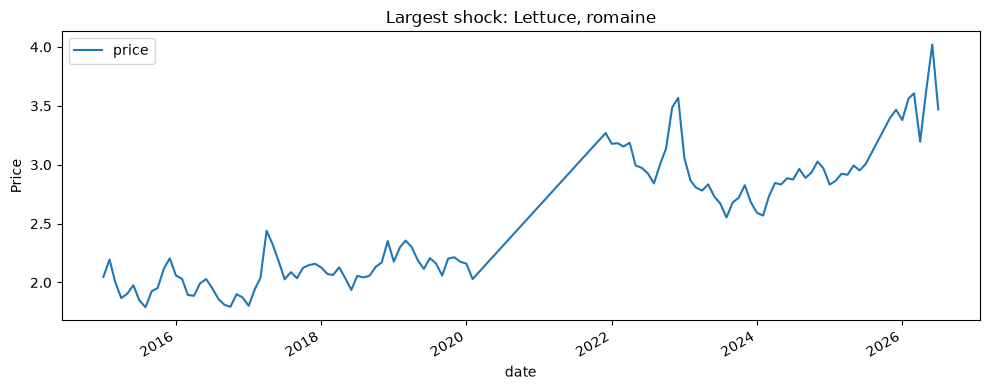

In [9]:
# Shocks: the largest month-over-month price moves
eda['pct_change'] = eda.groupby(ITEM, observed=True)[PRICE].pct_change() * 100
shocks = eda.reindex(eda['pct_change'].abs().sort_values(ascending=False).index).head(10)
display(shocks[[DATE, ITEM, CAT, PRICE, 'pct_change']].round(2))

# Plot the item with the single largest move
top_item = shocks.iloc[0][ITEM]
eda[eda[ITEM] == top_item].plot(x=DATE, y=PRICE, figsize=(10, 4), title=f'Largest shock: {top_item}')
plt.ylabel('Price'); plt.tight_layout(); plt.show()

**What this means:** (1) Prices trend upward over time at different speeds by category, so `year` is an important feature and models must be tested on later dates than they were trained on. (2) Seasonal swings are small compared with the long-term trend, so `month` adds some signal but less than `year` and `item`. (3) A few items have sudden spikes (for example eggs), which no model using only item and date can anticipate, so we expect the largest errors on those items. We confirm this in the model notebooks.